In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

In [26]:
df = pd.read_csv("Tweets.csv")

# Keep only required columns
df = df[['text', 'airline_sentiment']]

print(df.head())
print(df.shape)
print(df.info())
print(df.describe(include='all'))
print(df['airline_sentiment'].value_counts())

                                                text airline_sentiment
0                @VirginAmerica What @dhepburn said.           neutral
1  @VirginAmerica plus you've added commercials t...          positive
2  @VirginAmerica I didn't today... Must mean I n...           neutral
3  @VirginAmerica it's really aggressive to blast...          negative
4  @VirginAmerica and it's a really big bad thing...          negative
(14640, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   text               14640 non-null  object
 1   airline_sentiment  14640 non-null  object
dtypes: object(2)
memory usage: 228.9+ KB
None
                  text airline_sentiment
count            14640             14640
unique           14427                 3
top     @united thanks          negative
freq                 6              9178
airline_sentime

In [27]:
print(df.isnull().sum())

text                 0
airline_sentiment    0
dtype: int64


In [28]:
df.duplicated().sum()

np.int64(188)

In [29]:
df['tweet_length'] = df['text'].apply(len)

df['word_count'] = df['text'].apply(lambda x: len(x.split()))

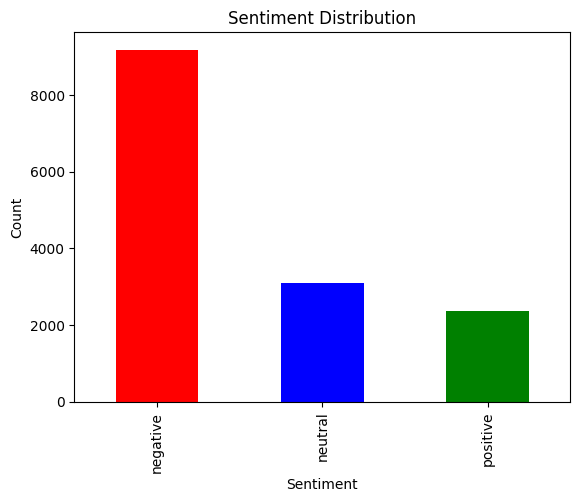

In [30]:
df['airline_sentiment'].value_counts().plot(
    kind='bar',
    color=['red','blue','green']
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

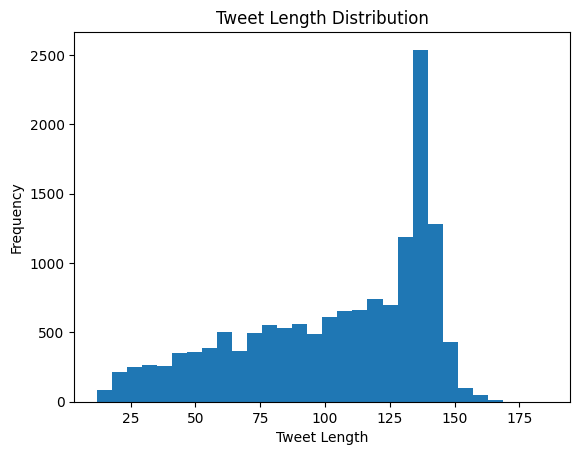

In [31]:
plt.hist(df['tweet_length'], bins=30)

plt.title("Tweet Length Distribution")
plt.xlabel("Tweet Length")
plt.ylabel("Frequency")

plt.show()

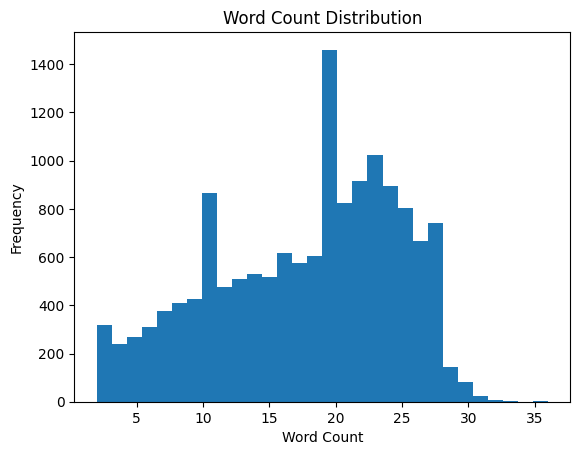

In [32]:
plt.hist(df['word_count'], bins=30)

plt.title("Word Count Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")

plt.show()

/tmp/ipykernel_6255/3788701053.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([


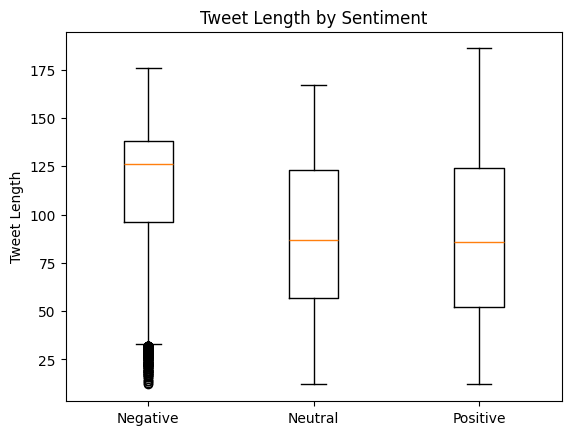

In [33]:
plt.boxplot([
    df[df['airline_sentiment']=="negative"]['tweet_length'],
    df[df['airline_sentiment']=="neutral"]['tweet_length'],
    df[df['airline_sentiment']=="positive"]['tweet_length']
],
labels=["Negative","Neutral","Positive"])

plt.title("Tweet Length by Sentiment")
plt.ylabel("Tweet Length")

plt.show()

# Key Insights

1. The dataset contains three sentiment classes: negative, neutral, and positive.
2. Negative tweets are the most frequent, while positive tweets are the least frequent, indicating class imbalance.
3. Most tweets are short in length, as shown by the tweet length and word count distributions.
4. Negative tweets have a higher median tweet length than positive and neutral tweets.
5. The engineered features (tweet_length and word_count) provide useful information about tweet characteristics before building the LSTM model.

In [34]:
encoder = LabelEncoder()

df['label'] = encoder.fit_transform(df['airline_sentiment'])

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'],
    df['label'],
    test_size=0.2,
    random_state=42
)

In [36]:
tokenizer = Tokenizer(num_words=5000)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)

X_test_seq = tokenizer.texts_to_sequences(X_test)

In [37]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=50
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=50
)

print(X_train_pad.shape)
print(X_test_pad.shape)

(11712, 50)
(2928, 50)


In [38]:
model = Sequential()

model.add(Embedding(
    input_dim=5000,
    output_dim=32,
    input_length=50
))

model.add(LSTM(32))

model.add(Dense(
    3,
    activation='softmax'
))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [39]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    validation_data=(X_test_pad,y_test),
    verbose=1
)

Epoch 1/5
366/366 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.7141 - loss: 0.7002 - val_accuracy: 0.7835 - val_loss: 0.5409
Epoch 2/5
366/366 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8316 - loss: 0.4370 - val_accuracy: 0.7869 - val_loss: 0.5198
Epoch 3/5
366/366 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.8745 - loss: 0.3362 - val_accuracy: 0.8009 - val_loss: 0.5198
Epoch 4/5
366/366 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8989 - loss: 0.2754 - val_accuracy: 0.7982 - val_loss: 0.5594
Epoch 5/5
366/366 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9138 - loss: 0.2401 - val_accuracy: 0.8046 - val_loss: 0.5975


In [40]:
loss, accuracy = model.evaluate(
    X_test_pad,
    y_test
)

print("Test Accuracy:",accuracy)

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8046 - loss: 0.5975
Test Accuracy: 0.8046448230743408


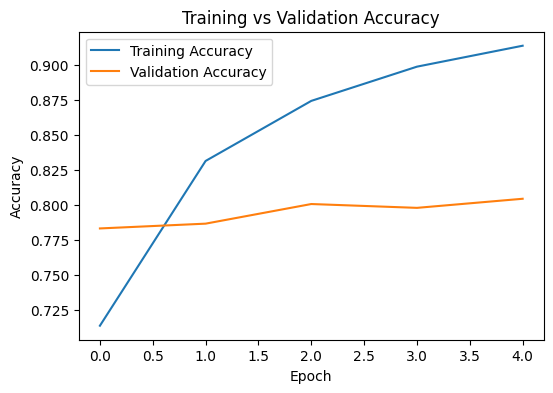

In [41]:
plt.figure(figsize=(6,4))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

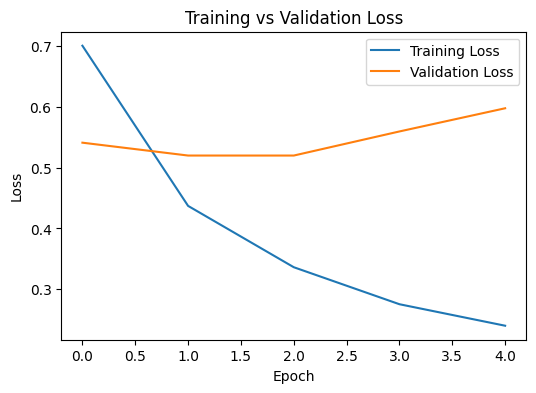

In [42]:
plt.figure(figsize=(6,4))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

## Forget Gate in LSTM

The forget gate allows an LSTM to remove unnecessary information from its memory while retaining important long-term information. This helps overcome the vanishing gradient problem and enables the model to learn long-term dependencies better than a plain RNN.